In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

RANDOM_STATE = 0

In [2]:
# Load dataset

In [2]:
df = pd.read_csv('../data/clean/cleaned_dataframe.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            61069 non-null  int64  
 1   class                 61069 non-null  str    
 2   cap-color             61069 non-null  str    
 3   cap-shape             61069 non-null  str    
 4   does-bruise-or-bleed  61069 non-null  str    
 5   gill-color            61069 non-null  str    
 6   has-ring              61069 non-null  str    
 7   season                61069 non-null  str    
 8   habitat               61069 non-null  str    
 9   cap-diameter          61069 non-null  float64
 10  stem-height           61069 non-null  float64
 11  stem-width            61069 non-null  float64
dtypes: float64(3), int64(1), str(8)
memory usage: 5.6 MB


In [4]:
# Drop Unnamed column
df = df.drop(columns="Unnamed: 0")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 61069 non-null  str    
 1   cap-color             61069 non-null  str    
 2   cap-shape             61069 non-null  str    
 3   does-bruise-or-bleed  61069 non-null  str    
 4   gill-color            61069 non-null  str    
 5   has-ring              61069 non-null  str    
 6   season                61069 non-null  str    
 7   habitat               61069 non-null  str    
 8   cap-diameter          61069 non-null  float64
 9   stem-height           61069 non-null  float64
 10  stem-width            61069 non-null  float64
dtypes: float64(3), str(8)
memory usage: 5.1 MB


In [5]:
# We split the data into train and test

X_mush = df.drop(columns="class")
y_mush = df["class"]

X_train_mush, X_test_mush, y_train_mush, y_test_mush = train_test_split(
    X_mush,
    y_mush,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_mush,
)

print("Training observations:", len(X_train_mush))
print("Test observations:", len(X_test_mush))
print("Training features:", list(X_train_mush.columns))

Training observations: 48855
Test observations: 12214
Training features: ['cap-color', 'cap-shape', 'does-bruise-or-bleed', 'gill-color', 'has-ring', 'season', 'habitat', 'cap-diameter', 'stem-height', 'stem-width']


In [6]:
# Split features by type
numeric_features = ["cap-diameter", 'stem-height', 'stem-width']
nominal_features = [ "cap-color", "cap-shape","does-bruise-or-bleed", "gill-color", "has-ring", "season", "habitat"]


In [7]:
# Define the enconder for Nominal features

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train_mush[nominal_features])

encoded_train = pd.DataFrame(
    encoder.transform(X_train_mush[nominal_features]),
    columns=encoder.get_feature_names_out(),
    index=X_train_mush.index,
)
display(encoded_train.head())


,cap-color_b,cap-color_e,cap-color_g,cap-color_k,cap-color_l,cap-color_n,cap-color_o,cap-color_p,cap-color_r,cap-color_u,...,season_u,season_w,habitat_d,habitat_g,habitat_h,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
1117,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32619,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
12883,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
43050,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
20204,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
# Creating a pipeline for Nominal features

nominal_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore', dtype=np.float32))
])

print(nominal_pipeline)

Pipeline(steps=[('encoder',
                 OneHotEncoder(dtype=<class 'numpy.float32'>,
                               handle_unknown='ignore'))])


In [9]:
# Scale Numerical features
scaler = StandardScaler()

scaled_train = pd.DataFrame(
    scaler.fit_transform(X_train_mush[numeric_features]),
    columns=numeric_features,
    index=X_train_mush.index,
)

scaled_test = pd.DataFrame(
    scaler.transform(X_test_mush[numeric_features]),
    columns=numeric_features,
    index=X_test_mush.index,
)

In [10]:
# Creating a pipeline for Numerical features

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', scaler),
])

print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [12]:
# descision tree pipeline
tree_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("nominal", OneHotEncoder(handle_unknown="ignore"), nominal_features),
])

tree_model = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("tree", DecisionTreeClassifier(max_depth= 5, min_samples_leaf= 1,random_state=RANDOM_STATE)),
])

tree_model.fit(X_train_mush, y_train_mush)
y_pred_tree = tree_model.predict(X_test_mush)

print("descision tree")
print(f"Training accuracy: {tree_model.score(X_train_mush, y_train_mush):.2%}")
print(f"Test accuracy:     {tree_model.score(X_test_mush, y_test_mush):.2%}")

descision tree
Training accuracy: 68.47%
Test accuracy:     68.18%


Best params: {'tree__class_weight': 'balanced', 'tree__max_depth': None, 'tree__min_samples_leaf': 1}

CV recall (poisonous): 0.9816 ± 0.0014
CV balanced accuracy:  0.9788 ± 0.0027
Train - CV gap:        0.0209
CV precision (edible): 0.9770 ± 0.0017
              precision    recall  f1-score   support

      Edible       0.98      0.98      0.98      5436
   Poisonous       0.98      0.98      0.98      6778

    accuracy                           0.98     12214
   macro avg       0.98      0.98      0.98     12214
weighted avg       0.98      0.98      0.98     12214



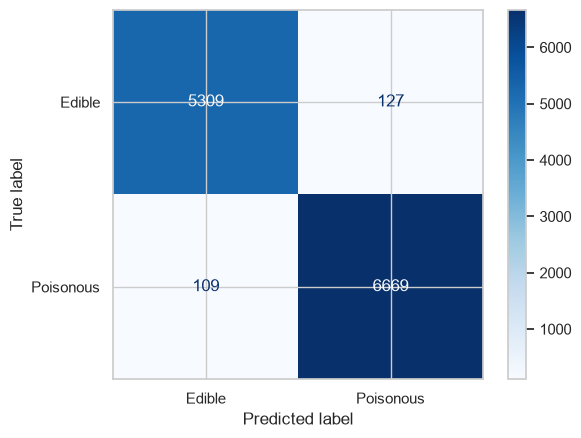

Training accuracy: 100.00%
Test accuracy:     98.07%


In [17]:
# Tune depth / leaf size with cross-validation
# An unpruned tree memorises the training data; tuning shows how much
# complexity you really need. Scoring on recall of the poisonous class
# keeps the focus on the costly error (poisonous predicted as edible).
# ============================================================
from sklearn.metrics import make_scorer, recall_score, precision_score

param_grid = {
    "tree__max_depth": [3, 5, 8, 12, 20, None],
    "tree__min_samples_leaf": [1, 5, 20],
    "tree__class_weight": [None, "balanced"],
}

# Same scorers every teammate must use
scoring = {
    "accuracy":        "accuracy",
    "balanced_acc":    "balanced_accuracy",
    "recall_poison":   make_scorer(recall_score, pos_label="p"),
    "precision_edible": make_scorer(precision_score, pos_label="e"),
}

grid = GridSearchCV(
    tree_model, param_grid,
    scoring=scoring,
    refit="balanced_acc",              # pick the best tree by balanced accuracy
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    return_train_score=True,
    n_jobs= -1,
)
grid.fit(X_train_mush, y_train_mush)
best_tree = grid.best_estimator_
print("Best params:", grid.best_params_)

# --- the three validation numbers for the best tree (5-fold CV) ---
i = grid.best_index_
r = grid.cv_results_
cv_recall  = r["mean_test_recall_poison"][i]
cv_bal_acc = r["mean_test_balanced_acc"][i]
prec_edible = r["mean_test_precision_edible"][i]
gap         = r["mean_train_accuracy"][i] - r["mean_test_accuracy"][i]

print(f"\nCV recall (poisonous): {cv_recall:.4f} ± {r['std_test_recall_poison'][i]:.4f}")
print(f"CV balanced accuracy:  {cv_bal_acc:.4f} ± {r['std_test_balanced_acc'][i]:.4f}")
print(f"Train - CV gap:        {gap:.4f}")
print(f"CV precision (edible): {prec_edible:.4f} ± {r['std_test_precision_edible'][i]:.4f}")

# --- held-out test set (single evaluation) ---
y_pred_tree = best_tree.predict(X_test_mush)
print(classification_report(y_test_mush, y_pred_tree, labels=["e", "p"],
                            target_names=["Edible", "Poisonous"]))
ConfusionMatrixDisplay.from_predictions(
    y_test_mush, y_pred_tree, labels=["e", "p"],
    display_labels=["Edible", "Poisonous"], cmap="Blues")
plt.show()

print(f"Training accuracy: {best_tree.score(X_train_mush, y_train_mush):.2%}")
print(f"Test accuracy:     {best_tree.score(X_test_mush, y_test_mush):.2%}")

In [ ]:
print(f"Best CV balanced accuracy: {grid.best_score_:.4f}")

cv_results = pd.DataFrame(grid.cv_results_)
cv_results[["params", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(10)

In [ ]:
def comparison_line(name, cv_recall, cv_bal_acc, prec_edible, gap):
    line = f"{name:<20} | recall_poison {cv_recall:.4f} | bal_acc {cv_bal_acc:.4f} | gap {gap:.4f}"
    print(line)
    pd.DataFrame([{"model": name, "cv_recall_poison": cv_recall,
                   "cv_bal_acc": cv_bal_acc, "train_cv_gap": gap}]) \
      .to_csv(f"results_{name.lower().replace(' ', '_')}.csv", index=False)

comparison_line("Decision Tree", cv_recall, cv_bal_acc, gap)

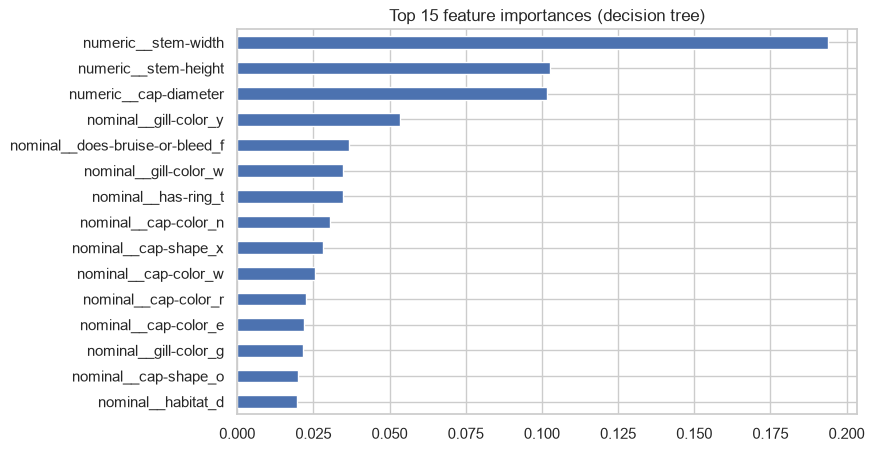

|--- numeric__stem-width <= 8.56
|   |--- numeric__stem-height <= 4.17
|   |   |--- nominal__gill-color_g <= 0.50
|   |   |   |--- numeric__stem-width <= 5.15
|   |   |   |   |--- nominal__cap-shape_b <= 0.50
|   |   |   |   |   |--- truncated branch of depth 10
|   |   |   |   |--- nominal__cap-shape_b >  0.50
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- numeric__stem-width >  5.15
|   |   |   |   |--- nominal__cap-color_w <= 0.50
|   |   |   |   |   |--- truncated branch of depth 12
|   |   |   |   |--- nominal__cap-color_w >  0.50
|   |   |   |   |   |--- truncated branch of depth 7
|   |   |--- nominal__gill-color_g >  0.50
|   |   |   |--- nominal__habitat_d <= 0.50
|   |   |   |   |--- numeric__stem-width <= 1.54
|   |   |   |   |   |--- class: e
|   |   |   |   |--- numeric__stem-width >  1.54
|   |   |   |   |   |--- class: p
|   |   |   |--- nominal__habitat_d >  0.50
|   |   |   |   |--- nominal__has-ring_t <= 0.50
|   |   |   |   |   |--- truncated b

In [15]:

# CELL 5 - Interpret the tree
feat_names = best_tree.named_steps["preprocessing"].get_feature_names_out()
importances = (pd.Series(best_tree.named_steps["tree"].feature_importances_,
                         index=feat_names)
               .sort_values(ascending=False).head(15))
importances.plot.barh(figsize=(8, 5)).invert_yaxis()
plt.title("Top 15 feature importances (decision tree)")
plt.show()

# Text view of the rules (only readable if max_depth is small)
print(export_text(best_tree.named_steps["tree"], feature_names=list(feat_names),
                  max_depth=4))
